# Telco — Semi-Supervised Churn Classification

Use the AE's latent representation (`z`) and reconstruction error as features for supervised classifiers.

**Experiments:**
- **Exp A** — Embedding-only classifiers (LR, RF, XGB) × feature variants
- **Exp B** — XGB hyperparameter tuning on best variant from A
- **Exp C** — Feature augmentation: base processed features + AE signal
- **Final** — Comparison table + ROC curves

**Splits:**  
`fit` (70%) → train classifiers | `stop` (15%) → threshold selection | `test` (15%) → evaluation

## 1. Setup

In [1]:
from __future__ import annotations
import sys
from pathlib import Path

_w4_root = Path().resolve()
if str(_w4_root) not in sys.path:
    sys.path.insert(0, str(_w4_root))

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, roc_curve, precision_recall_curve,
)
from xgboost import XGBClassifier

from constants import SEED, CHECKPOINTS_DIR, RUNS_DIR, FIGURES_DIR
from autoencoder.data_loader  import load_telco_data, filter_normal
from train.train_ae import load_checkpoint, set_seed

SS_RUNS_DIR    = RUNS_DIR / 'semi_supervised'
SS_FIGURES_DIR = SS_RUNS_DIR / 'figures'
SS_RUNS_DIR.mkdir(parents=True, exist_ok=True)
SS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH  = 2048
set_seed(SEED)
print('device:', DEVICE)

device: cpu


## 2. Data & AE checkpoint

In [2]:
df, y_all, _, categorical, numeric, split = load_telco_data()
fit_normal, stop_normal = filter_normal(split, y_all)

ae_model, ae_cfg, prep, _, _ = load_checkpoint(CHECKPOINTS_DIR / 'ae_best.pt', DEVICE)
ae_model.eval()
print(f'AE z_dim={ae_cfg.z_dim}  |  preprocessor: numeric_dim={prep.numeric_dim}')

# Full labeled splits
fit_idx  = split['fit']
stop_idx = split['stop']
test_idx = split['test']

df_fit  = df.iloc[fit_idx].reset_index(drop=True)
df_stop = df.iloc[stop_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)

y_fit  = y_all[fit_idx]
y_stop = y_all[stop_idx]
y_test = y_all[test_idx]

x_num_fit,  x_cat_fit  = prep.transform(df_fit)
x_num_stop, x_cat_stop = prep.transform(df_stop)
x_num_test, x_cat_test = prep.transform(df_test)

print(f'fit  : {len(x_num_fit):>5,}   churn={y_fit.sum():>4,}  ({y_fit.mean():.2%})')
print(f'stop : {len(x_num_stop):>5,}   churn={y_stop.sum():>4,}  ({y_stop.mean():.2%})')
print(f'test : {len(x_num_test):>5,}   churn={y_test.sum():>4,}  ({y_test.mean():.2%})')

AE z_dim=16  |  preprocessor: numeric_dim=4
fit  : 4,930   churn=1,308  (26.53%)
stop : 1,056   churn= 280  (26.52%)
test : 1,057   churn= 281  (26.58%)


## 3. Embedding & reconstruction helpers

In [3]:
def _batches(x_num, x_cat, batch_size, device):
    for i in range(0, len(x_num), batch_size):
        yield x_num[i:i+batch_size].to(device), x_cat[i:i+batch_size].to(device)


def extract_latent(model, x_num, x_cat, device=DEVICE, batch_size=BATCH):
    """Return z (latent vector) for each sample."""
    model.eval()
    parts = []
    with torch.no_grad():
        for bn, bc in _batches(x_num, x_cat, batch_size, device):
            parts.append(model.encode(bn, bc).cpu())
    return torch.cat(parts).numpy()


def recon_error(model, x_num, x_cat, device=DEVICE, batch_size=BATCH):
    """Per-sample reconstruction error (MSE_num + CE_cat, summed over features)."""
    model.eval()
    parts = []
    with torch.no_grad():
        for bn, bc in _batches(x_num, x_cat, batch_size, device):
            _, num_out, cat_logits = model(bn, bc)
            num_err = F.mse_loss(num_out, bn, reduction='none').sum(dim=-1)
            cat_err = torch.stack(
                [F.cross_entropy(logits, bc[:, k], reduction='none')
                 for k, logits in enumerate(cat_logits)], dim=1
            ).sum(dim=1)
            parts.append((num_err + cat_err).cpu())
    return torch.cat(parts).numpy()


def build_base(x_num, x_cat, prep):
    """Concatenate standardised numerics + one-hot categoricals into one matrix."""
    oh_parts = [
        F.one_hot(x_cat[:, i].long(), card).float().numpy()
        for i, card in enumerate(prep.cat_cardinalities)
    ]
    return np.hstack([x_num.numpy()] + oh_parts)


print('Extracting AE features...')
feats = {}
for name, (xn, xc) in [('fit', (x_num_fit, x_cat_fit)),
                        ('stop',(x_num_stop, x_cat_stop)),
                        ('test',(x_num_test, x_cat_test))]:
    feats[name] = {
        'z':    extract_latent(ae_model, xn, xc),
        'recon': recon_error(ae_model, xn, xc).reshape(-1, 1),
        'base':  build_base(xn, xc, prep),
    }
    print(f'  {name}: z{feats[name]["z"].shape}  recon{feats[name]["recon"].shape}  base{feats[name]["base"].shape}')
print('Done.')

Extracting AE features...
  fit: z(4930, 16)  recon(4930, 1)  base(4930, 60)
  stop: z(1056, 16)  recon(1056, 1)  base(1056, 60)
  test: z(1057, 16)  recon(1057, 1)  base(1057, 60)
Done.


## 4. Feature variants

In [4]:
def build_variants(f):
    z, r, b = f['z'], f['recon'], f['base']
    return {
        'z_AE':          z,
        'z_AE + recon':  np.hstack([z, r]),
        'base only':     b,
        'base + recon':  np.hstack([b, r]),
        'base + z_AE':   np.hstack([b, z]),
        'base + z + r':  np.hstack([b, z, r]),
    }

variants = {split_name: build_variants(feats[split_name])
            for split_name in ('fit', 'stop', 'test')}

print('Feature variants:')
for name, arr in variants['fit'].items():
    print(f'  {name:<22}  dims={arr.shape[1]}')

Feature variants:
  z_AE                    dims=16
  z_AE + recon            dims=17
  base only               dims=60
  base + recon            dims=61
  base + z_AE             dims=76
  base + z + r            dims=77


## 5. Shared evaluation utilities

In [5]:
def best_f1_threshold(y_true, y_prob):
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
    denom = precision[:-1] + recall[:-1]
    f1 = np.where(denom > 0, 2 * precision[:-1] * recall[:-1] / denom, 0.0)
    return float(thresholds[np.argmax(f1)])


def evaluate(y_true, y_prob, threshold, clf_name, feat_name):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return {
        'classifier':        clf_name,
        'features':          feat_name,
        'model':             f'{clf_name}({feat_name})',
        'roc_auc':           float(roc_auc_score(y_true, y_prob)),
        'average_precision': float(average_precision_score(y_true, y_prob)),
        'threshold':         float(threshold),
        'precision_churn':   float(prec),
        'recall_churn':      float(rec),
        'f1_churn':          float(f1),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }


def run_exp(
    clf_template,
    X_fit, X_stop, X_test,
    y_fit, y_stop, y_test,
    clf_name, feat_name,
):
    """Train on fit, select threshold on stop, evaluate on test."""
    scaler    = StandardScaler()
    X_fit_sc  = scaler.fit_transform(X_fit)
    X_stop_sc = scaler.transform(X_stop)
    X_test_sc = scaler.transform(X_test)

    clf = clone(clf_template)
    clf.fit(X_fit_sc, y_fit)

    threshold = best_f1_threshold(y_stop, clf.predict_proba(X_stop_sc)[:, 1])
    return evaluate(y_test, clf.predict_proba(X_test_sc)[:, 1], threshold, clf_name, feat_name)


SHOW = ['model', 'roc_auc', 'average_precision', 'f1_churn', 'recall_churn', 'precision_churn']
scale_pos = float((y_fit == 0).sum() / (y_fit == 1).sum())
print(f'scale_pos_weight: {scale_pos:.2f}  (class imbalance ratio)')

scale_pos_weight: 2.77  (class imbalance ratio)


## 6. Experiment A — 3 classifiers × 6 feature variants

In [6]:
classifiers = {
    'LR':  LogisticRegression(class_weight='balanced', max_iter=1000,
                               random_state=SEED, solver='lbfgs'),
    'RF':  RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                   random_state=SEED, n_jobs=-1),
    'XGB': XGBClassifier(n_estimators=200, scale_pos_weight=scale_pos,
                          learning_rate=0.05, max_depth=4,
                          random_state=SEED, eval_metric='logloss', verbosity=0),
}

rows_a = []
for clf_name, clf_template in classifiers.items():
    for feat_name in variants['fit']:
        row = run_exp(
            clf_template,
            variants['fit'][feat_name], variants['stop'][feat_name], variants['test'][feat_name],
            y_fit, y_stop, y_test,
            clf_name, feat_name,
        )
        rows_a.append(row)
        print(f'  {clf_name:4s}  {feat_name:22s}  AUC={row["roc_auc"]:.4f}  F1={row["f1_churn"]:.4f}')

exp_a = pd.DataFrame(rows_a)
exp_a.to_csv(SS_RUNS_DIR / 'exp_a_results.csv', index=False)
print('\nSaved exp_a_results.csv')

  LR    z_AE                    AUC=0.8459  F1=0.6376
  LR    z_AE + recon            AUC=0.8450  F1=0.6385
  LR    base only               AUC=0.8494  F1=0.6333
  LR    base + recon            AUC=0.8479  F1=0.6408
  LR    base + z_AE             AUC=0.8492  F1=0.6311
  LR    base + z + r            AUC=0.8481  F1=0.6399
  RF    z_AE                    AUC=0.8244  F1=0.6057
  RF    z_AE + recon            AUC=0.8235  F1=0.6146
  RF    base only               AUC=0.8283  F1=0.6149
  RF    base + recon            AUC=0.8294  F1=0.6205
  RF    base + z_AE             AUC=0.8253  F1=0.6088
  RF    base + z + r            AUC=0.8241  F1=0.6076
  XGB   z_AE                    AUC=0.8399  F1=0.6154
  XGB   z_AE + recon            AUC=0.8387  F1=0.6234
  XGB   base only               AUC=0.8480  F1=0.6331
  XGB   base + recon            AUC=0.8465  F1=0.6276
  XGB   base + z_AE             AUC=0.8426  F1=0.6270
  XGB   base + z + r            AUC=0.8415  F1=0.6372

Saved exp_a_results.csv


### 6a. Exp A — AUC heatmap

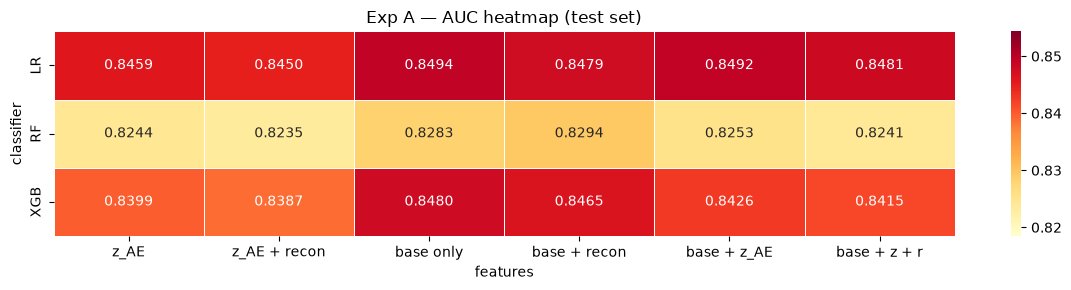


            model  roc_auc  average_precision  f1_churn  recall_churn  precision_churn
    LR(base only)   0.8494             0.6540    0.6333        0.6975           0.5799
  LR(base + z_AE)   0.8492             0.6526    0.6311        0.6940           0.5786
 LR(base + z + r)   0.8481             0.6517    0.6399        0.7082           0.5836
   XGB(base only)   0.8480             0.6668    0.6331        0.7829           0.5314
 LR(base + recon)   0.8479             0.6522    0.6408        0.7046           0.5875
XGB(base + recon)   0.8465             0.6566    0.6276        0.8007           0.5161
         LR(z_AE)   0.8459             0.6594    0.6376        0.7544           0.5521
 LR(z_AE + recon)   0.8450             0.6564    0.6385        0.7260           0.5698
 XGB(base + z_AE)   0.8426             0.6515    0.6270        0.7865           0.5212
XGB(base + z + r)   0.8415             0.6462    0.6372        0.7438           0.5573
        XGB(z_AE)   0.8399             0.6

In [7]:
pivot = exp_a.pivot(index='classifier', columns='features', values='roc_auc')
pivot = pivot.reindex(index=list(classifiers.keys()),
                      columns=list(variants['fit'].keys()))

fig, ax = plt.subplots(figsize=(12, 3))
sns.heatmap(pivot, annot=True, fmt='.4f', cmap='YlOrRd',
            vmin=pivot.values.min() - 0.005,
            vmax=pivot.values.max() + 0.005,
            linewidths=0.5, ax=ax)
ax.set_title('Exp A — AUC heatmap (test set)')
plt.tight_layout()
plt.savefig(SS_FIGURES_DIR / 'exp_a_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print()
print(exp_a[SHOW].sort_values('roc_auc', ascending=False)
      .to_string(index=False, float_format=lambda x: f'{x:.4f}'))

## 7. Experiment B — XGB hyperparameter tuning

Take top-2 feature variants from Exp A and tune XGB depth/regularization.

In [8]:
top2_feats = (exp_a.sort_values('roc_auc', ascending=False)
              .head(4)['features'].unique()[:2].tolist())
print('Top-2 feature variants:', top2_feats)

xgb_configs = {
    'XGB_base': XGBClassifier(n_estimators=200, scale_pos_weight=scale_pos,
                               learning_rate=0.05, max_depth=4,
                               random_state=SEED, eval_metric='logloss', verbosity=0),
    'XGB_deep': XGBClassifier(n_estimators=300, scale_pos_weight=scale_pos,
                               learning_rate=0.03, max_depth=6,
                               random_state=SEED, eval_metric='logloss', verbosity=0),
    'XGB_reg':  XGBClassifier(n_estimators=300, scale_pos_weight=scale_pos,
                               learning_rate=0.05, max_depth=5,
                               subsample=0.8, colsample_bytree=0.8,
                               min_child_weight=5, reg_lambda=1.5,
                               random_state=SEED, eval_metric='logloss', verbosity=0),
}

rows_b = []
for xgb_name, xgb_clf in xgb_configs.items():
    for feat_name in top2_feats:
        row = run_exp(
            xgb_clf,
            variants['fit'][feat_name], variants['stop'][feat_name], variants['test'][feat_name],
            y_fit, y_stop, y_test,
            xgb_name, feat_name,
        )
        rows_b.append(row)
        print(f'  {xgb_name:10s}  {feat_name:22s}  AUC={row["roc_auc"]:.4f}  F1={row["f1_churn"]:.4f}')

exp_b = pd.DataFrame(rows_b)
exp_b.to_csv(SS_RUNS_DIR / 'exp_b_xgb_tuning.csv', index=False)
print()
print(exp_b[SHOW].sort_values('roc_auc', ascending=False)
      .to_string(index=False, float_format=lambda x: f'{x:.4f}'))

Top-2 feature variants: ['base only', 'base + z_AE']
  XGB_base    base only               AUC=0.8480  F1=0.6331
  XGB_base    base + z_AE             AUC=0.8426  F1=0.6270
  XGB_deep    base only               AUC=0.8389  F1=0.6239
  XGB_deep    base + z_AE             AUC=0.8334  F1=0.6100
  XGB_reg     base only               AUC=0.8424  F1=0.6436
  XGB_reg     base + z_AE             AUC=0.8331  F1=0.6175

                model  roc_auc  average_precision  f1_churn  recall_churn  precision_churn
  XGB_base(base only)   0.8480             0.6668    0.6331        0.7829           0.5314
XGB_base(base + z_AE)   0.8426             0.6515    0.6270        0.7865           0.5212
   XGB_reg(base only)   0.8424             0.6496    0.6436        0.7616           0.5573
  XGB_deep(base only)   0.8389             0.6489    0.6239        0.7794           0.5202
XGB_deep(base + z_AE)   0.8334             0.6366    0.6100        0.6762           0.5556
 XGB_reg(base + z_AE)   0.8331          

## 8. Experiment C — Augmented training data

Add the unlabeled non-churn pool (`fit_normal` + `stop_normal`) as extra negative examples  
to the best embedding variant. This exploits the full unsupervised training corpus.

In [9]:
extra_idx = np.concatenate([fit_normal, stop_normal])
df_extra  = df.iloc[extra_idx].reset_index(drop=True)
y_extra   = np.zeros(len(extra_idx), dtype=np.int32)

x_num_extra, x_cat_extra = prep.transform(df_extra)
z_extra    = extract_latent(ae_model, x_num_extra, x_cat_extra)
recon_extra = recon_error(ae_model, x_num_extra, x_cat_extra).reshape(-1, 1)
base_extra  = build_base(x_num_extra, x_cat_extra, prep)
print(f'Extra non-churn pool: {len(extra_idx):,}')

best_feat_aug = (
    pd.concat([exp_a, exp_b])
    .sort_values('roc_auc', ascending=False)
    .iloc[0]['features']
)
print(f'Best feature variant for augmentation: {best_feat_aug}')

extra_variants = build_variants({'z': z_extra, 'recon': recon_extra, 'base': base_extra})

X_aug = np.vstack([extra_variants[best_feat_aug], variants['fit'][best_feat_aug]])
y_aug = np.concatenate([y_extra, y_fit])
scale_pos_aug = float((y_aug == 0).sum() / (y_aug == 1).sum())
print(f'Augmented train: {len(X_aug):,}  churn={y_aug.sum():,}  ({y_aug.mean():.2%})')

aug_clfs = {
    'XGB_aug': XGBClassifier(n_estimators=300, scale_pos_weight=scale_pos_aug,
                              learning_rate=0.05, max_depth=5, subsample=0.8,
                              colsample_bytree=0.8, min_child_weight=5, reg_lambda=1.5,
                              random_state=SEED, eval_metric='logloss', verbosity=0),
    'RF_aug':  RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                       random_state=SEED, n_jobs=-1),
}

rows_c = []
scaler_aug  = StandardScaler()
X_aug_sc    = scaler_aug.fit_transform(X_aug)
X_stop_aug  = scaler_aug.transform(variants['stop'][best_feat_aug])
X_test_aug  = scaler_aug.transform(variants['test'][best_feat_aug])

for clf_name, clf_template in aug_clfs.items():
    clf = clone(clf_template)
    clf.fit(X_aug_sc, y_aug)
    threshold = best_f1_threshold(y_stop, clf.predict_proba(X_stop_aug)[:, 1])
    row = evaluate(y_test, clf.predict_proba(X_test_aug)[:, 1],
                   threshold, clf_name, best_feat_aug)
    rows_c.append(row)
    print(f'  {clf_name:10s}  AUC={row["roc_auc"]:.4f}  F1={row["f1_churn"]:.4f}')

exp_c = pd.DataFrame(rows_c)
exp_c.to_csv(SS_RUNS_DIR / 'exp_c_augmented.csv', index=False)

Extra non-churn pool: 4,398
Best feature variant for augmentation: base only
Augmented train: 9,328  churn=1,308  (14.02%)
  XGB_aug     AUC=0.8389  F1=0.6185
  RF_aug      AUC=0.8168  F1=0.5838


## 9. Final comparison

In [10]:
COMPARE_COLS = ['model', 'method', 'roc_auc', 'average_precision',
                'f1_churn', 'recall_churn', 'precision_churn']

def tag(df, method):
    d = df[SHOW].copy()
    d['method'] = method
    return d[COMPARE_COLS]

best_a_per_clf = (exp_a.sort_values('roc_auc', ascending=False)
                  .groupby('classifier').first().reset_index())

final = pd.concat([
    tag(best_a_per_clf,                              'Exp A — best per clf'),
    tag(exp_b.sort_values('roc_auc', ascending=False).head(3), 'Exp B — XGB tuning'),
    tag(exp_c,                                        'Exp C — augmented data'),
], ignore_index=True).sort_values('roc_auc', ascending=False).reset_index(drop=True)

print(final.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
final.to_csv(SS_RUNS_DIR / 'final_comparison.csv', index=False)

                model                 method  roc_auc  average_precision  f1_churn  recall_churn  precision_churn
        LR(base only)   Exp A — best per clf   0.8494             0.6540    0.6333        0.6975           0.5799
       XGB(base only)   Exp A — best per clf   0.8480             0.6668    0.6331        0.7829           0.5314
  XGB_base(base only)     Exp B — XGB tuning   0.8480             0.6668    0.6331        0.7829           0.5314
XGB_base(base + z_AE)     Exp B — XGB tuning   0.8426             0.6515    0.6270        0.7865           0.5212
   XGB_reg(base only)     Exp B — XGB tuning   0.8424             0.6496    0.6436        0.7616           0.5573
   XGB_aug(base only) Exp C — augmented data   0.8389             0.6537    0.6185        0.8221           0.4957
     RF(base + recon)   Exp A — best per clf   0.8294             0.6145    0.6205        0.7651           0.5218
    RF_aug(base only) Exp C — augmented data   0.8168             0.6009    0.5838      

### 9a. ROC curves — best of each experiment

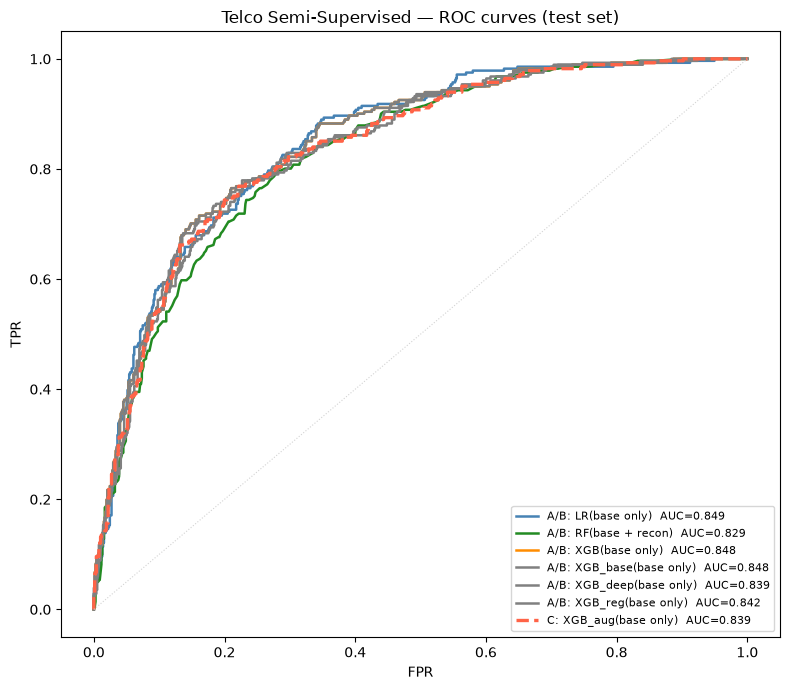

In [11]:
palette = {'LR': 'steelblue', 'RF': 'forestgreen', 'XGB': 'darkorange',
           'XGB_aug': 'tomato', 'RF_aug': 'mediumpurple'}

fig, ax = plt.subplots(figsize=(8, 7))

# Best per classifier from Exp A/B
best_rows = (pd.concat([exp_a, exp_b])
             .sort_values('roc_auc', ascending=False)
             .groupby('classifier').first().reset_index())

for _, row in best_rows.iterrows():
    cn, fn = row['classifier'], row['features']
    clf_tpl = {
        'LR': classifiers['LR'], 'RF': classifiers['RF'],
        'XGB': classifiers['XGB'],
        'XGB_base': xgb_configs['XGB_base'],
        'XGB_deep': xgb_configs['XGB_deep'],
        'XGB_reg':  xgb_configs['XGB_reg'],
    }.get(cn)
    if clf_tpl is None:
        continue
    sc = StandardScaler()
    Xtr = sc.fit_transform(variants['fit'][fn])
    Xte = sc.transform(variants['test'][fn])
    clf = clone(clf_tpl)
    clf.fit(Xtr, y_fit)
    yp = clf.predict_proba(Xte)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, yp)
    auc = roc_auc_score(y_test, yp)
    color = palette.get(cn, 'gray')
    ax.plot(fpr, tpr, color=color, linewidth=1.8,
            label=f'A/B: {cn}({fn})  AUC={auc:.3f}')

# Exp C — augmented XGB
sc_c = StandardScaler()
Xtr_c = sc_c.fit_transform(X_aug)
Xte_c = sc_c.transform(variants['test'][best_feat_aug])
clf_c = clone(aug_clfs['XGB_aug'])
clf_c.fit(Xtr_c, y_aug)
yp_c = clf_c.predict_proba(Xte_c)[:, 1]
fpr_c, tpr_c, _ = roc_curve(y_test, yp_c)
ax.plot(fpr_c, tpr_c, color='tomato', linewidth=2.4, linestyle='--',
        label=f'C: XGB_aug({best_feat_aug})  AUC={roc_auc_score(y_test, yp_c):.3f}')

ax.plot([0, 1], [0, 1], color='lightgray', linewidth=0.8, linestyle=':')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.set_title('Telco Semi-Supervised — ROC curves (test set)')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(SS_FIGURES_DIR / 'roc_all.png', dpi=150, bbox_inches='tight')
plt.show()

### 9b. Precision-Recall curves

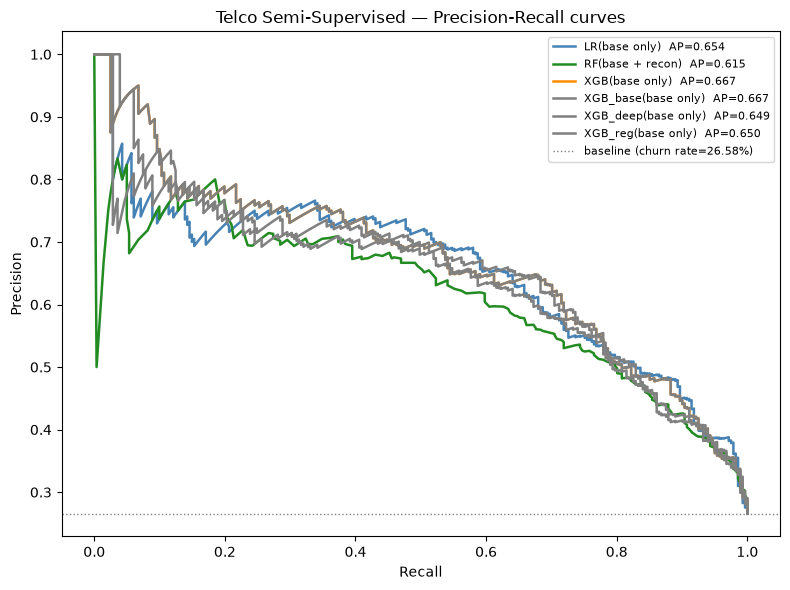

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
baseline_ap = y_test.mean()

for _, row in best_rows.iterrows():
    cn, fn = row['classifier'], row['features']
    clf_tpl = {
        'LR': classifiers['LR'], 'RF': classifiers['RF'],
        'XGB': classifiers['XGB'],
        'XGB_base': xgb_configs['XGB_base'],
        'XGB_deep': xgb_configs['XGB_deep'],
        'XGB_reg':  xgb_configs['XGB_reg'],
    }.get(cn)
    if clf_tpl is None:
        continue
    sc = StandardScaler()
    Xtr = sc.fit_transform(variants['fit'][fn])
    Xte = sc.transform(variants['test'][fn])
    clf = clone(clf_tpl)
    clf.fit(Xtr, y_fit)
    yp = clf.predict_proba(Xte)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, yp)
    ap = average_precision_score(y_test, yp)
    ax.plot(rec, prec, color=palette.get(cn, 'gray'), linewidth=1.8,
            label=f'{cn}({fn})  AP={ap:.3f}')

ax.axhline(baseline_ap, color='gray', linestyle=':', linewidth=1.0,
           label=f'baseline (churn rate={baseline_ap:.2%})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Telco Semi-Supervised — Precision-Recall curves')
ax.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.savefig(SS_FIGURES_DIR / 'pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Summary

In [13]:
all_exps = [
    ('Exp A', exp_a),
    ('Exp B', exp_b),
    ('Exp C', exp_c),
]

print('=== Best per experiment ===')
print(f'{"Exp":<8}  {"Best model":<40}  {"AUC":>6}  {"AP":>6}  {"F1":>6}  {"Recall":>6}')
print('-' * 80)
for exp_name, exp_df in all_exps:
    b = exp_df.sort_values('roc_auc', ascending=False).iloc[0]
    print(f'{exp_name:<8}  {b["model"]:<40}  {b["roc_auc"]:.4f}  '
          f'{b["average_precision"]:.4f}  {b["f1_churn"]:.4f}  {b["recall_churn"]:.4f}')

all_rows = pd.concat([e for _, e in all_exps])
best_auc = all_rows.sort_values('roc_auc', ascending=False).iloc[0]
best_f1  = all_rows.sort_values('f1_churn', ascending=False).iloc[0]

print()
print(f'Overall best AUC : {best_auc["model"]}  AUC={best_auc["roc_auc"]:.4f}')
print(f'Overall best F1  : {best_f1["model"]}  F1={best_f1["f1_churn"]:.4f}')

=== Best per experiment ===
Exp       Best model                                   AUC      AP      F1  Recall
--------------------------------------------------------------------------------
Exp A     LR(base only)                             0.8494  0.6540  0.6333  0.6975
Exp B     XGB_base(base only)                       0.8480  0.6668  0.6331  0.7829
Exp C     XGB_aug(base only)                        0.8389  0.6537  0.6185  0.8221

Overall best AUC : LR(base only)  AUC=0.8494
Overall best F1  : XGB_reg(base only)  F1=0.6436


## 11. Comparison vs W1 Supervised Models

Compare the best semi-supervised experiments (seed=110 test set) against the four W1 supervised baselines (seed=42 test set).
Both test splits share identical characteristics: **1,057 rows, ~26.6% churn**.
- **W1 XGBoost / Neural Network** are re-evaluated here using their saved checkpoints on the W1 test data.
- **W1 LogReg / Random Forest** metrics are sourced directly from their training notebooks (no checkpoint was saved).

W1 test: (1057, 47)  churn=281 (26.58%)

W1 models:
            model  roc_auc  average_precision  f1_churn  recall_churn  precision_churn
       W1 XGBoost   0.8439             0.6714    0.6296        0.7046           0.5690
W1 Neural Network   0.8370             0.6405    0.6301        0.6335           0.6268
        W1 LogReg   0.8446             0.6584    0.6311        0.7580           0.5406
 W1 Random Forest   0.8413             0.6724    0.6227        0.6726           0.5798

=== W1 Supervised vs Semi-Supervised AE (sorted by AUC) ===
              model               method  roc_auc  average_precision  f1_churn  recall_churn  precision_churn
      LR(base only) Exp A — best per clf   0.8494             0.6540    0.6333        0.6975           0.5799
     XGB(base only) Exp A — best per clf   0.8480             0.6668    0.6331        0.7829           0.5314
XGB_base(base only)   Exp B — XGB tuning   0.8480             0.6668    0.6331        0.7829           0.5314
          W1

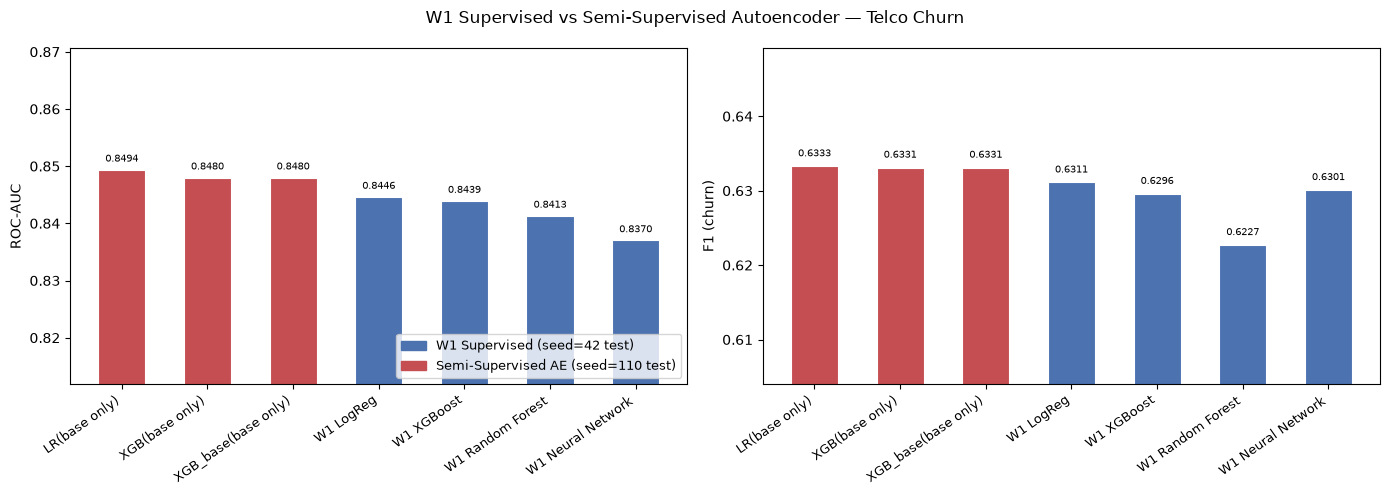


Note: W1 models evaluated on seed=42 test set | Semi-supervised on seed=110 test set
      Both splits: 1,057 rows, ~26.6% churn rate.


In [14]:
from constants import PROJECT_ROOT, DATA_DIR

import pickle
import torch.nn as nn

# ---- W1 paths & data -------------------------------------------------------
W1_CKPT_DIR = PROJECT_ROOT / "src" / "w1_supervized_learning" / "checkpoints"

npz       = np.load(DATA_DIR / "telco_preprocessed_splits.npz")
X_w1_test = npz["X_test"].astype(np.float32)
y_w1_test = npz["y_test"].astype(np.int32)
print(f"W1 test: {X_w1_test.shape}  churn={y_w1_test.sum()} ({y_w1_test.mean():.2%})")


# ---- FlexibleMLP (mirrors the W1 NN notebook) ------------------------------
class FlexibleMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, dropout_p=0.0, use_batchnorm=False):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev, h))
            if use_batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout_p > 0:
                layers.append(nn.Dropout(dropout_p))
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


# ---- Shared evaluation (threshold already chosen in W1) --------------------
def _eval_w1(y_true, y_prob, threshold, model_name):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return {
        "model":             model_name,
        "method":            "W1 Supervised",
        "roc_auc":           float(roc_auc_score(y_true, y_prob)),
        "average_precision": float(average_precision_score(y_true, y_prob)),
        "f1_churn":          float(f1),
        "recall_churn":      float(rec),
        "precision_churn":   float(prec),
    }


w1_rows = []

# ---- W1 XGBoost ------------------------------------------------------------
with open(W1_CKPT_DIR / "xgboost_telco.pkl", "rb") as fh:
    xgb_ckpt = pickle.load(fh)
xgb_proba = xgb_ckpt["model"].predict_proba(X_w1_test)[:, 1]
w1_rows.append(_eval_w1(y_w1_test, xgb_proba, xgb_ckpt["threshold"], "W1 XGBoost"))

# ---- W1 Neural Network -----------------------------------------------------
with open(W1_CKPT_DIR / "neural_network_telco.pkl", "rb") as fh:
    nn_ckpt = pickle.load(fh)
cfg   = nn_ckpt["model_config"]
nn_w1 = FlexibleMLP(
    input_dim=cfg["input_dim"],
    hidden_dims=cfg["hidden_dims"],
    dropout_p=cfg["dropout_p"],
    use_batchnorm=cfg["use_batchnorm"],
)
nn_w1.load_state_dict(nn_ckpt["state_dict"])
nn_w1.eval()
with torch.no_grad():
    nn_proba = torch.sigmoid(nn_w1(torch.tensor(X_w1_test)).squeeze(-1)).numpy()
w1_rows.append(_eval_w1(y_w1_test, nn_proba, nn_ckpt["threshold"], "W1 Neural Network"))

# ---- W1 LR and RF (hardcoded — no checkpoints saved) -----------------------
w1_rows.append({
    "model": "W1 LogReg",   "method": "W1 Supervised",
    "roc_auc": 0.8446, "average_precision": 0.6584,
    "f1_churn": 0.6311, "recall_churn": 0.7580, "precision_churn": 0.5406,
})
w1_rows.append({
    "model": "W1 Random Forest", "method": "W1 Supervised",
    "roc_auc": 0.8413, "average_precision": 0.6724,
    "f1_churn": 0.6227, "recall_churn": 0.6726, "precision_churn": 0.5798,
})

df_w1 = pd.DataFrame(w1_rows)
print()
print("W1 models:")
print(df_w1[["model", "roc_auc", "average_precision", "f1_churn", "recall_churn", "precision_churn"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- Best semi-supervised results (top-3 by AUC from Section 9) ------------
COMPARE_COLS_11 = ["model", "method", "roc_auc", "average_precision",
                   "f1_churn", "recall_churn", "precision_churn"]
ss_final = pd.read_csv(SS_RUNS_DIR / "final_comparison.csv")
ss_top3  = ss_final.sort_values("roc_auc", ascending=False).head(3).copy()
ss_top3  = ss_top3[COMPARE_COLS_11]

combined = (
    pd.concat([df_w1[COMPARE_COLS_11], ss_top3], ignore_index=True)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)
combined.to_csv(SS_RUNS_DIR / "w1_vs_semisup.csv", index=False)
print()
print("=== W1 Supervised vs Semi-Supervised AE (sorted by AUC) ===")
print(combined.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- Grouped bar chart: AUC and F1 ----------------------------------------
from matplotlib.patches import Patch

_colors = ["#4c72b0" if m == "W1 Supervised" else "#c44e52"
           for m in combined["method"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(combined))

for ax, metric, ylabel in [
    (axes[0], "roc_auc",  "ROC-AUC"),
    (axes[1], "f1_churn", "F1 (churn)"),
]:
    bars = ax.bar(x, combined[metric], color=_colors, width=0.55,
                  edgecolor="white", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(combined["model"], rotation=35, ha="right", fontsize=9)
    ax.set_ylabel(ylabel)
    ax.set_ylim(combined[metric].min() * 0.97, combined[metric].max() * 1.025)
    for bar, val in zip(bars, combined[metric]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.001,
                f"{val:.4f}", ha="center", va="bottom", fontsize=7.5)

axes[0].legend(handles=[
    Patch(color="#4c72b0", label="W1 Supervised (seed=42 test)"),
    Patch(color="#c44e52", label="Semi-Supervised AE (seed=110 test)"),
], fontsize=9, loc="lower right")

plt.suptitle("W1 Supervised vs Semi-Supervised Autoencoder — Telco Churn", fontsize=12)
plt.tight_layout()
plt.savefig(SS_FIGURES_DIR / "w1_vs_semisup.png", dpi=150, bbox_inches="tight")
plt.show()
print()
print("Note: W1 models evaluated on seed=42 test set | Semi-supervised on seed=110 test set")
print("      Both splits: 1,057 rows, ~26.6% churn rate.")
